In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf

In [2]:
tickers = [
    "SPY",
    "QQQ",
    "TLT",
    "GLD",
    "EURUSD=X"
]

data = yf.download(
    tickers,
    start="2021-01-01",
    end="2026-11-07",
    auto_adjust=True
)

data.head()

[*********************100%***********************]  5 of 5 completed


Price          Close                                                  \
Ticker      EURUSD=X         GLD         QQQ         SPY         TLT   
Date                                                                   
2021-01-01  1.218027         NaN         NaN         NaN         NaN   
2021-01-04  1.225070  182.330002  299.144348  341.588806  130.697357   
2021-01-05  1.225160  182.869995  301.610474  343.941376  129.726654   
2021-01-06  1.230027  179.899994  297.432495  345.997559  127.063629   
2021-01-07  1.234111  179.479996  304.627930  351.138214  125.943626   

Price           High                                                  ...  \
Ticker      EURUSD=X         GLD         QQQ         SPY         TLT  ...   
Date                                                                  ...   
2021-01-01  1.221699         NaN         NaN         NaN         NaN  ...   
2021-01-04  1.230999  182.399994  304.927823  347.757581  131.228310  ...   
2021-01-05  1.229483  183.210007  301.881300  345.025091  130.207831  ...   
2021-01-06  1.235025  181.580002  301.629854  349.174589  127.636065  ...   
2021-01-07  1.234568  179.919998  305.459651  351.879196  126.242288  ...   

Price           Open                                                   Volume  \
Ticker      EURUSD=X         GLD         QQQ         SPY         TLT EURUSD=X   
Date                                                                            
2021-01-01  1.217285         NaN         NaN         NaN         NaN      0.0   
2021-01-04  1.224905  181.970001  304.753716  347.627894  129.975597      0.0   
2021-01-05  1.225295  182.869995  298.157827  340.949633  130.207831      0.0   
2021-01-06  1.229861  181.490005  296.910234  342.440794  127.611177      0.0   
2021-01-07  1.233776  179.690002  300.082387  348.359489  125.927031      0.0   

Price                                                        
Ticker             GLD         QQQ          SPY         TLT  
Date                                                         
2021-01-01         NaN         NaN          NaN         NaN  
2021-01-04  14331400.0  45305900.0  110210800.0  13152900.0  
2021-01-05  12718800.0  29323400.0   66426200.0  10458100.0  
2021-01-06  18453500.0  52809600.0  107997700.0  22827300.0  
2021-01-07   7110200.0  30394800.0   68766800.0  14651900.0  

[5 rows x 25 columns]

In [3]:
data.columns

MultiIndex([( 'Close', 'EURUSD=X'),
            ( 'Close',      'GLD'),
            ( 'Close',      'QQQ'),
            ( 'Close',      'SPY'),
            ( 'Close',      'TLT'),
            (  'High', 'EURUSD=X'),
            (  'High',      'GLD'),
            (  'High',      'QQQ'),
            (  'High',      'SPY'),
            (  'High',      'TLT'),
            (   'Low', 'EURUSD=X'),
            (   'Low',      'GLD'),
            (   'Low',      'QQQ'),
            (   'Low',      'SPY'),
            (   'Low',      'TLT'),
            (  'Open', 'EURUSD=X'),
            (  'Open',      'GLD'),
            (  'Open',      'QQQ'),
            (  'Open',      'SPY'),
            (  'Open',      'TLT'),
            ('Volume', 'EURUSD=X'),
            ('Volume',      'GLD'),
            ('Volume',      'QQQ'),
            ('Volume',      'SPY'),
            ('Volume',      'TLT')],
           names=['Price', 'Ticker'])

In [4]:
prices = data["Close"].copy()

prices.head()

Ticker,EURUSD=X,GLD,QQQ,SPY,TLT
Date,,,,,
2021-01-01,1.218027,NaN,NaN,NaN,NaN
2021-01-04,1.225070,182.330002,299.144348,341.588806,130.697357
2021-01-05,1.225160,182.869995,301.610474,343.941376,129.726654
2021-01-06,1.230027,179.899994,297.432495,345.997559,127.063629
2021-01-07,1.234111,179.479996,304.627930,351.138214,125.943626


In [5]:
print(prices.shape)
print(prices.isnull().sum())

(1522, 5)
Ticker
EURUSD=X     1
GLD         53
QQQ         53
SPY         53
TLT         53
dtype: int64


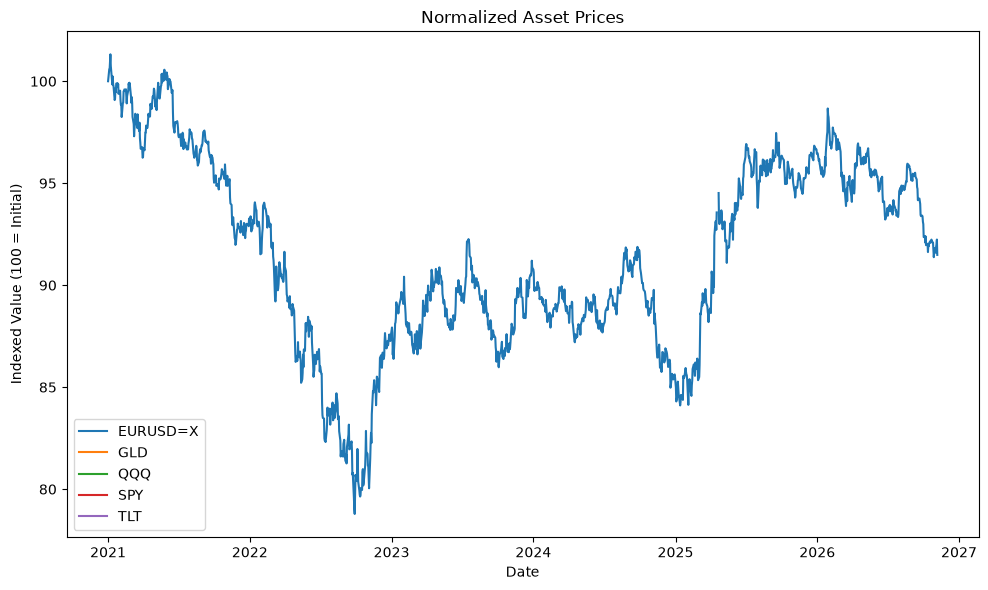

In [6]:
normalized_prices = (
    prices / prices.iloc[0]
) * 100

plt.figure(figsize=(10, 6))

for column in normalized_prices.columns:
    plt.plot(
        normalized_prices.index,
        normalized_prices[column],
        label=column
    )

plt.title("Normalized Asset Prices")
plt.xlabel("Date")
plt.ylabel("Indexed Value (100 = Initial)")
plt.legend()

plt.tight_layout()

plt.savefig(
    "../reports/figures/normalized_asset_prices.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [7]:
returns = prices.pct_change().dropna()

returns.head()

Ticker,EURUSD=X,GLD,QQQ,SPY,TLT
Date,,,,,
2021-01-05,0.000074,0.002962,0.008244,0.006887,-0.007427
2021-01-06,0.003973,-0.016241,-0.013852,0.005978,-0.020528
2021-01-07,0.003320,-0.002335,0.024192,0.014857,-0.008815
2021-01-08,-0.005645,-0.034210,0.012858,0.005698,-0.003227
2021-01-11,-0.006946,-0.001961,-0.014450,-0.006741,-0.001652


In [8]:
returns.describe()

Ticker,EURUSD=X,GLD,QQQ,SPY,TLT
count,1414.000000,1414.000000,1414.000000,1414.000000,1414.000000
mean,-0.000073,0.000536,0.000686,0.000649,-0.000145
std,0.004651,0.011598,0.014269,0.010500,0.009565
min,-0.018418,-0.102742,-0.064889,-0.058543,-0.034182
25%,-0.002647,-0.005298,-0.006552,-0.004454,-0.006397
50%,-0.000235,0.000597,0.001145,0.000877,-0.000116
75%,0.002654,0.006659,0.008560,0.006323,0.005697
max,0.027919,0.063587,0.120031,0.105019,0.038474


In [9]:
prices.to_csv(
    "../data/processed/market_prices.csv"
)

returns.to_csv(
    "../data/processed/daily_returns.csv"
)

In [10]:
prices_aligned = prices.dropna().copy()

returns = (
    prices_aligned
    .pct_change(fill_method=None)
    .dropna()
)

print("Aligned prices:", prices_aligned.shape)
print("Returns:", returns.shape)
print("\nMissing returns:")
print(returns.isnull().sum())

Aligned prices: (1468, 5)
Returns: (1467, 5)

Missing returns:
Ticker
EURUSD=X    0
GLD         0
QQQ         0
SPY         0
TLT         0
dtype: int64


In [11]:
extremes = []

for ticker in returns.columns:

    min_date = returns[ticker].idxmin()
    max_date = returns[ticker].idxmax()

    extremes.append({
        "Ticker": ticker,
        "Min Return": returns.loc[min_date, ticker],
        "Min Date": min_date,
        "Max Return": returns.loc[max_date, ticker],
        "Max Date": max_date
    })

extremes_df = pd.DataFrame(extremes)

extremes_df

,Ticker,Min Return,Min Date,Max Return,Max Date
0,EURUSD=X,-0.018418,2024-11-07,0.027919,2025-04-11
1,GLD,-0.102742,2026-01-30,0.063587,2026-02-03
2,QQQ,-0.064889,2026-11-05,0.120031,2025-04-09
3,SPY,-0.058543,2025-04-04,0.105019,2025-04-09
4,TLT,-0.034182,2022-03-02,0.038474,2022-11-10


In [12]:
portfolio_value = 1_000_000

In [13]:
weights = pd.Series({
    "SPY": 0.30,
    "QQQ": 0.20,
    "TLT": 0.25,
    "GLD": 0.15,
    "EURUSD=X": 0.10
})

weights = weights.reindex(returns.columns)

print(weights)
print("\nTotal weight:", weights.sum())

Ticker
EURUSD=X    0.10
GLD         0.15
QQQ         0.20
SPY         0.30
TLT         0.25
dtype: float64

Total weight: 1.0


In [14]:
portfolio_returns = (
    returns
    .mul(weights, axis=1)
    .sum(axis=1)
)

portfolio_returns.head()

Date
2021-01-05    0.002310
2021-01-06   -0.008148
2021-01-07    0.007074
2021-01-08   -0.002222
2021-01-11   -0.006314
dtype: float64

In [15]:
portfolio_pnl = (
    portfolio_returns
    * portfolio_value
)

portfolio_pnl.head()

Date
2021-01-05    2309.751883
2021-01-06   -8147.809207
2021-01-07    7073.769144
2021-01-08   -2221.957662
2021-01-11   -6314.056374
dtype: float64

In [16]:
portfolio_stats = pd.Series({
    "Daily Mean Return": portfolio_returns.mean(),
    "Daily Volatility": portfolio_returns.std(),
    "Annualized Return": portfolio_returns.mean() * 252,
    "Annualized Volatility": portfolio_returns.std() * np.sqrt(252),
    "Worst Daily Return": portfolio_returns.min(),
    "Best Daily Return": portfolio_returns.max(),
    "Worst Daily P&L": portfolio_pnl.min(),
    "Best Daily P&L": portfolio_pnl.max()
})

portfolio_stats

Daily Mean Return            0.000312
Daily Volatility             0.007167
Annualized Return            0.078677
Annualized Volatility        0.113771
Worst Daily Return          -0.033713
Best Daily Return            0.063128
Worst Daily P&L         -33713.154008
Best Daily P&L           63128.384742
dtype: float64

In [17]:
correlation_matrix = returns.corr()

correlation_matrix

Ticker,EURUSD=X,GLD,QQQ,SPY,TLT
Ticker,,,,,
EURUSD=X,1.000000,0.012945,-0.015371,-0.009442,0.033891
GLD,0.012945,1.000000,0.168812,0.173231,0.210755
QQQ,-0.015371,0.168812,1.000000,0.942453,0.081343
SPY,-0.009442,0.173231,0.942453,1.000000,0.073739
TLT,0.033891,0.210755,0.081343,0.073739,1.000000


In [18]:
portfolio_df = pd.DataFrame({
    "PortfolioReturn": portfolio_returns,
    "PortfolioPnL": portfolio_pnl
})

portfolio_df.to_csv(
    "../data/processed/portfolio_returns.csv"
)